# BigMart Sales Prediction - Data cleaning and exploration

In [128]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

print("shape:", train.shape)
print("shape:", test.shape)
train.head()

shape: (8523, 12)
shape: (5681, 11)


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


## 1. First look

In [129]:
train.head()

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


In [130]:
test.head()

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type
0,FDW58,20.750,Low Fat,0.007565,Snack Foods,107.8622,OUT049,1999,Medium,Tier 1,Supermarket Type1
1,FDW14,8.300,reg,0.038428,Dairy,87.3198,OUT017,2007,NaN,Tier 2,Supermarket Type1
2,NCN55,14.600,Low Fat,0.099575,Others,241.7538,OUT010,1998,NaN,Tier 3,Grocery Store
3,FDQ58,7.315,Low Fat,0.015388,Snack Foods,155.0340,OUT017,2007,NaN,Tier 2,Supermarket Type1
4,FDY38,NaN,Regular,0.118599,Dairy,234.2300,OUT027,1985,Medium,Tier 3,Supermarket Type3


In [131]:
# missing values
print("Train:")
print(train.isnull().sum())

print()

print("Test:")
print(test.isnull().sum())

Train:
Item_Identifier                 0
Item_Weight                  1463
Item_Fat_Content                0
Item_Visibility                 0
Item_Type                       0
Item_MRP                        0
Outlet_Identifier               0
Outlet_Establishment_Year       0
Outlet_Size                  2410
Outlet_Location_Type            0
Outlet_Type                     0
Item_Outlet_Sales               0
dtype: int64

Test:
Item_Identifier                 0
Item_Weight                   976
Item_Fat_Content                0
Item_Visibility                 0
Item_Type                       0
Item_MRP                        0
Outlet_Identifier               0
Outlet_Establishment_Year       0
Outlet_Size                  1606
Outlet_Location_Type            0
Outlet_Type                     0
dtype: int64


Columns that have missing values: "Item_Weight" and "Outlet_Size"

Looking at "Item_Fat_Content"

In [132]:
print(train["Item_Fat_Content"].value_counts())

Item_Fat_Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64


In [133]:
summary = train.groupby("Outlet_Identifier").agg(
    outlet_type=("Outlet_Type", "first"),
    outlet_size=("Outlet_Size", "first"),
    missing_rows=("Outlet_Size", lambda x: x.isna().sum()),
    total_rows=("Outlet_Size", "size")
)

print(summary)

                         outlet_type outlet_size  missing_rows  total_rows
Outlet_Identifier                                                         
OUT010                 Grocery Store         NaN           555         555
OUT013             Supermarket Type1        High             0         932
OUT017             Supermarket Type1         NaN           926         926
OUT018             Supermarket Type2      Medium             0         928
OUT019                 Grocery Store       Small             0         528
OUT027             Supermarket Type3      Medium             0         935
OUT035             Supermarket Type1       Small             0         930
OUT045             Supermarket Type1         NaN           929         929
OUT046             Supermarket Type1       Small             0         930
OUT049             Supermarket Type1      Medium             0         930


"Outlet_Size" is missing for OUT010, OUT017, OUT045

- OUT010 is a Grocery Store, and the other grocery store (OUT019) is Small.
- OUT017 and OUT045 are Supermarket Type1 in Tier 2, and the similar store OUT035 is Small.

So I will fill all three with "Small"

Outlet_Type
Grocery Store         340.0
Supermarket Type2    1995.0
Supermarket Type1    2316.0
Supermarket Type3    3694.0
Name: Item_Outlet_Sales, dtype: float64


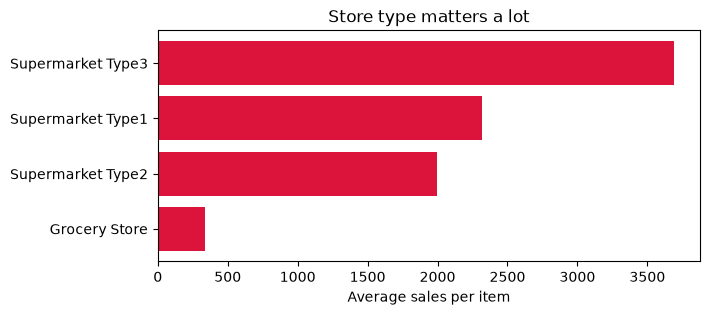

In [134]:
# average sales for each store type
avg_by_type = train.groupby("Outlet_Type")["Item_Outlet_Sales"].mean().sort_values()
print(avg_by_type.round())

plt.figure(figsize=(7, 3))
plt.barh(avg_by_type.index, avg_by_type.values, color='crimson')
plt.xlabel("Average sales per item")
plt.title("Store type matters a lot")
plt.show()

Grocery store sells 340 per item    /       Supermarket Type3 about Rs 3,694

more than a 10x diff, just from the store.

In [135]:
print(train.corr(numeric_only=True)["Item_Outlet_Sales"].sort_values())

Item_Visibility             -0.128625
Outlet_Establishment_Year   -0.049135
Item_Weight                  0.014123
Item_MRP                     0.567574
Item_Outlet_Sales            1.000000
Name: Item_Outlet_Sales, dtype: float64


"Item_MRP" has a correlation of 0.57. So "price" and "store" are significant.

## 2. Cleaning

In [136]:
train["is_train"] = 1
test["is_train"] = 0
df = pd.concat([train, test], ignore_index=True)
print(df.shape)

(14204, 13)


In [137]:
# Fix 1: fat content labels
df["Item_Fat_Content"] = df["Item_Fat_Content"].replace("LF", "Low Fat")
df["Item_Fat_Content"] = df["Item_Fat_Content"].replace("low fat", "Low Fat")
df["Item_Fat_Content"] = df["Item_Fat_Content"].replace("reg", "Regular")

# item codes start with FD (food), DR (drinks) or NC (non-consumable)
df["Item_Category"] = df["Item_Identifier"].str[:2]

# non-consumables (soap etc.) can't have a fat content
df.loc[df["Item_Category"] == "NC", "Item_Fat_Content"] = "Non-Edible"

print(df["Item_Fat_Content"].value_counts())

Item_Fat_Content
Low Fat       6499
Regular       5019
Non-Edible    2686
Name: count, dtype: int64


In [138]:
# Fix 2: missing weights
df["Item_Weight"] = df["Item_Weight"].fillna(
    df.groupby("Item_Identifier")["Item_Weight"].transform("mean")
)

df["Item_Weight"] = df["Item_Weight"].fillna(
    df.groupby("Item_Type")["Item_Weight"].transform("median")
)

print("Missing:", df["Item_Weight"].isnull().sum())

Missing: 0


In [139]:
# Fix 3: missing Outlet_Size
df["Outlet_Size"] = df["Outlet_Size"].fillna("Small")

print("Missing:", df["Outlet_Size"].isnull().sum())

Missing: 0


New columns

In [140]:
# Age of the store instead of the year it opened
df["Outlet_Age"] = 2013 - df["Outlet_Establishment_Year"]

# Price per kilo
df["Price_by_weight"] = df["Item_MRP"] / df["Item_Weight"]

df[["Item_Identifier", "Item_Category", "Item_Weight", "Outlet_Age", "Price_by_weight"]].head()

,Item_Identifier,Item_Category,Item_Weight,Outlet_Age,Price_by_weight
0,FDA15,FD,9.30,14,26.861204
1,DRC01,DR,5.92,4,8.153581
2,FDN15,FD,17.50,14,8.092457
3,FDX07,FD,19.20,15,9.484115
4,NCD19,NC,8.93,26,6.031512


## 3. sales = price x units

In [141]:
example = train[(train["Item_Identifier"] == 'FDA15')]
print(example[["Outlet_Identifier", "Item_MRP", "Item_Outlet_Sales"]].to_string(index=False))

# when we divide the sales by one of these prices, we get the number of items sold
print()
print("sales divided by 249.0092")
print((example['Item_Outlet_Sales'] / 249.0092).round(4).to_string(index=False))

Outlet_Identifier  Item_MRP  Item_Outlet_Sales
           OUT049  249.8092          3735.1380
           OUT045  250.2092          5976.2208
           OUT035  248.5092          6474.2392
           OUT018  249.6092          5976.2208
           OUT010  248.9092           498.0184
           OUT013  250.6092          6474.2392
           OUT027  249.5092          6474.2392
           OUT017  248.8092          5976.2208

sales divided by 249.0092
15.0
24.0
26.0
24.0
 2.0
26.0
26.0
24.0


In [143]:
# use the recovered price when we have it, otherwise just use Item_MRP
df["Base_Price"] = df["Item_Identifier"].map(true_prices).fillna(df['Item_MRP'])

df[["Item_Identifier", "Item_MRP", "Base_Price"]].head()

,Item_Identifier,Item_MRP,Base_Price
0,FDA15,249.8092,249.0092
1,DRC01,48.2692,49.2692
2,FDN15,141.6180,139.8180
3,FDX07,182.0950,183.0950
4,NCD19,53.8614,55.2614


## 4. Units sold

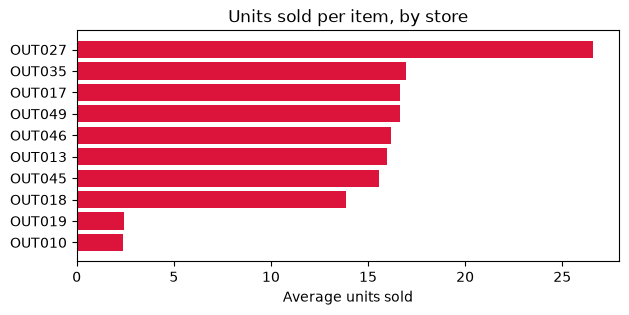

                         outlet_type
Outlet_Identifier                   
OUT010                 Grocery Store
OUT013             Supermarket Type1
OUT017             Supermarket Type1
OUT018             Supermarket Type2
OUT019                 Grocery Store
OUT027             Supermarket Type3
OUT035             Supermarket Type1
OUT045             Supermarket Type1
OUT046             Supermarket Type1
OUT049             Supermarket Type1


In [144]:
df['units'] = df['Item_Outlet_Sales'] / df['Base_Price']

train_part = df[df['is_train'] == 1]
units_by_store = train_part.groupby('Outlet_Identifier')['units'].mean().sort_values()
# print(units_by_store.round(1))

plt.figure(figsize=(7, 3))
plt.barh(units_by_store.index, units_by_store.values, color='crimson')
plt.xlabel('Average units sold')
plt.title('Units sold per item, by store')
plt.show()

summary = df.groupby("Outlet_Identifier").agg(
    outlet_type=("Outlet_Type", "first")
)
print(summary)

- The two grocery stores (OUT010 and OUT019) sell about 2.4 units.
- Most supermarkets sell about 16 units.
- OUT027 (Type3) sells about 26.6 units.

In [ ]:
print("Correlation of units and price, by store:")

for store in sorted(train_part['Outlet_Identifier'].unique()):
    rows = train_part[train_part['Outlet_Identifier'] == store]
    print(store, ':', round(rows['units'].corr(rows['Base_Price']), 3))

Correlation of units and price, by store:
OUT010 : 0.044
OUT013 : 0.08
OUT017 : 0.04
OUT018 : 0.082
OUT019 : -0.018
OUT027 : -0.044
OUT035 : 0.023
OUT045 : -0.007
OUT046 : -0.047
OUT049 : 0.038


All close to 0, so inside a store the units sold don't depend on the price. Good, the simple idea can work.

## 5. Save the cleaned data for the next notebook

In [146]:
clean_train = df[df['is_train'] == 1].reset_index(drop=True)
clean_test = df[df['is_train'] == 0].reset_index(drop=True)

# test has no sales or units
clean_test = clean_test.drop(columns=['Item_Outlet_Sales', 'units'])

clean_train.to_csv('train_clean.csv', index=False)
clean_test.to_csv('test_clean.csv', index=False)

print('saved train_clean.csv', clean_train.shape)
print('saved test_clean.csv', clean_test.shape)

saved train_clean.csv (8523, 18)
saved test_clean.csv (5681, 16)
